<a href="https://colab.research.google.com/github/ilsafaisal15/Intelligent-Multi-Class-Natural-Language-Text-Sentiment-Classifier/blob/main/Task1_NLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q datasets

import re, nltk, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, f1_score, ConfusionMatrixDisplay

nltk.download("stopwords"); nltk.download("wordnet"); nltk.download("omw-1.4")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
!pip install -q -U datasets huggingface_hub

from datasets import load_dataset
import pandas as pd

# Loading with the updated package or using the direct namespace identifier
ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")
train = pd.DataFrame(ds["train"]); val = pd.DataFrame(ds["validation"]); test = pd.DataFrame(ds["test"])
labels = ["negative", "neutral", "positive"]
print(train.shape, test.shape); train.head()

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (3 outputs left out)

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

(45615, 2) (12284, 2)


,text,label
0,"""QT @user In the original draft of the 7th boo...",2
1,"""Ben Smith / Smith (concussion) remains out of...",1
2,Sorry bout the stream last night I crashed out...,1
3,Chase Headley's RBI double in the 8th inning o...,1
4,@user Alciato: Bee will invest 150 million in ...,2


In [ ]:
lemmatizer = WordNetLemmatizer()
# Keep negations: "not good" loses its meaning if "not" is removed
stop = set(stopwords.words("english")) - {"no", "not", "nor", "never", "n't"}

def preprocess(text):
    text = text.lower()
    text = re.sub(r"http\S+|@\w+|#", "", text)      # URLs, mentions, hashtag symbols
    text = re.sub(r"[^a-z\s]", " ", text)           # punctuation, digits
    tokens = [lemmatizer.lemmatize(t) for t in text.split() if t not in stop]
    return " ".join(tokens)

for df in (train, val, test):
    df["clean"] = df["text"].apply(preprocess)

train[["text", "clean"]].head()

,text,clean
0,"""QT @user In the original draft of the 7th boo...",qt original draft th book remus lupin survived...
1,"""Ben Smith / Smith (concussion) remains out of...",ben smith smith concussion remains lineup thur...
2,Sorry bout the stream last night I crashed out...,sorry bout stream last night crashed tonight s...
3,Chase Headley's RBI double in the 8th inning o...,chase headley rbi double th inning david price...
4,@user Alciato: Bee will invest 150 million in ...,alciato bee invest million january another sum...


=== Logistic Regression Validation Performance ===
              precision    recall  f1-score   support

    negative       0.60      0.34      0.44       312
     neutral       0.63      0.75      0.68       869
    positive       0.72      0.69      0.71       819

    accuracy                           0.66      2000
   macro avg       0.65      0.60      0.61      2000
weighted avg       0.66      0.66      0.65      2000

=== Linear Support Vector Classifier Validation Performance ===
              precision    recall  f1-score   support

    negative       0.60      0.42      0.50       312
     neutral       0.64      0.72      0.68       869
    positive       0.72      0.71      0.71       819

    accuracy                           0.67      2000
   macro avg       0.65      0.62      0.63      2000
weighted avg       0.67      0.67      0.66      2000



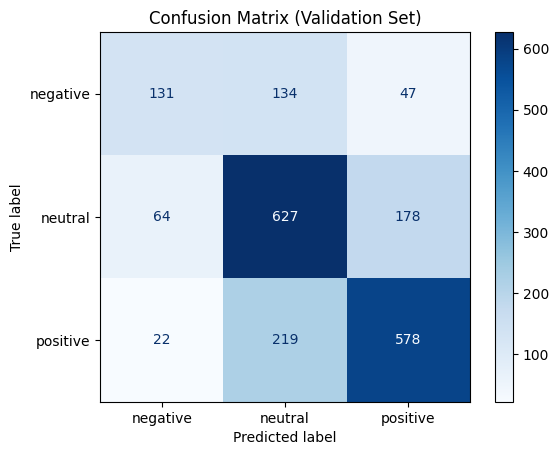

In [ ]:
# Initialize the TF-IDF Vectorizer
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))

# Vectorize the cleaned text fields
X_train = vectorizer.fit_transform(train["clean"])
X_val = vectorizer.transform(val["clean"])
X_test = vectorizer.transform(test["clean"])

y_train = train["label"]
y_val = val["label"]
y_test = test["label"]

# 1. Train and evaluate Logistic Regression
lr = LogisticRegression(max_iter=1000, C=1.0)
lr.fit(X_train, y_train)
lr_val_preds = lr.predict(X_val)

print("=== Logistic Regression Validation Performance ===")
print(classification_report(y_val, lr_val_preds, target_names=labels))

# 2. Train and evaluate Support Vector Machine (LinearSVC)
svc = LinearSVC(C=0.5, random_state=42)
svc.fit(X_train, y_train)
svc_val_preds = svc.predict(X_val)

print("=== Linear Support Vector Classifier Validation Performance ===")
print(classification_report(y_val, svc_val_preds, target_names=labels))

# Display confusion matrix for the better performing model on validation data
best_preds = svc_val_preds if f1_score(y_val, svc_val_preds, average='macro') > f1_score(y_val, lr_val_preds, average='macro') else lr_val_preds
ConfusionMatrixDisplay.from_predictions(y_val, best_preds, display_labels=labels, cmap=plt.cm.Blues)
plt.title("Confusion Matrix (Validation Set)")
plt.show()

=== Linear Support Vector Classifier TEST Set Performance ===
              precision    recall  f1-score   support

    negative       0.63      0.46      0.53      3972
     neutral       0.60      0.66      0.63      5937
    positive       0.49      0.59      0.54      2375

    accuracy                           0.58     12284
   macro avg       0.58      0.57      0.57     12284
weighted avg       0.59      0.58      0.58     12284



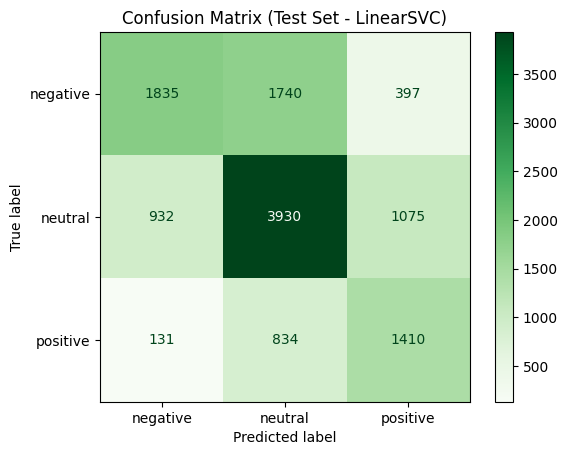

In [ ]:
# Evaluate the final Linear Support Vector Classifier on the test set
svc_test_preds = svc.predict(X_test)

print("=== Linear Support Vector Classifier TEST Set Performance ===")
print(classification_report(y_test, svc_test_preds, target_names=labels))

# Display confusion matrix for the final test evaluation
ConfusionMatrixDisplay.from_predictions(y_test, svc_test_preds, display_labels=labels, cmap=plt.cm.Greens)
plt.title("Confusion Matrix (Test Set - LinearSVC)")
plt.show()

In [ ]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000)
X_train = tfidf.fit_transform(train["clean"])   # fit ONLY on training data
X_val   = tfidf.transform(val["clean"])
X_test  = tfidf.transform(test["clean"])

=== Improved LinearSVC Validation Performance ===
              precision    recall  f1-score   support

    negative       0.60      0.42      0.50       312
     neutral       0.64      0.72      0.68       869
    positive       0.72      0.71      0.71       819

    accuracy                           0.67      2000
   macro avg       0.65      0.62      0.63      2000
weighted avg       0.67      0.67      0.66      2000

=== Improved LinearSVC TEST Set Performance ===
              precision    recall  f1-score   support

    negative       0.63      0.46      0.53      3972
     neutral       0.60      0.66      0.63      5937
    positive       0.49      0.59      0.54      2375

    accuracy                           0.58     12284
   macro avg       0.58      0.57      0.57     12284
weighted avg       0.59      0.58      0.58     12284



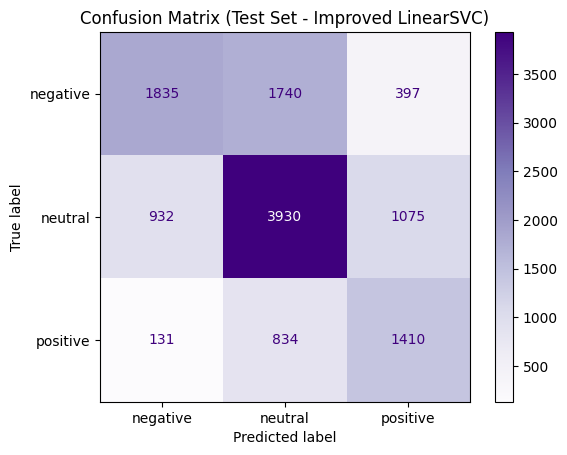

In [ ]:
# Retrain LinearSVC with the new 50k TF-IDF features
svc_improved = LinearSVC(C=0.5, random_state=42)
svc_improved.fit(X_train, y_train)

# Evaluate on the validation set
svc_improved_val_preds = svc_improved.predict(X_val)
print("=== Improved LinearSVC Validation Performance ===")
print(classification_report(y_val, svc_improved_val_preds, target_names=labels))

# Evaluate on the test set
svc_improved_test_preds = svc_improved.predict(X_test)
print("=== Improved LinearSVC TEST Set Performance ===")
print(classification_report(y_test, svc_improved_test_preds, target_names=labels))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, svc_improved_test_preds, display_labels=labels, cmap=plt.cm.Purples)
plt.title("Confusion Matrix (Test Set - Improved LinearSVC)")
plt.show()

In [ ]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "LinearSVC": LinearSVC(class_weight="balanced"),
}
for name, m in models.items():
    m.fit(X_train, train["label"])
    pred = m.predict(X_val)
    print(f"{name}: macro-F1 = {f1_score(val['label'], pred, average='macro'):.3f}")

LogisticRegression: macro-F1 = 0.636
LinearSVC: macro-F1 = 0.631


              precision    recall  f1-score   support

    negative       0.52      0.72      0.60      3972
     neutral       0.65      0.48      0.56      5937
    positive       0.54      0.55      0.55      2375

    accuracy                           0.57     12284
   macro avg       0.57      0.58      0.57     12284
weighted avg       0.59      0.57      0.57     12284

Macro F1:    0.5685252051220261
Weighted F1: 0.5691509748742842


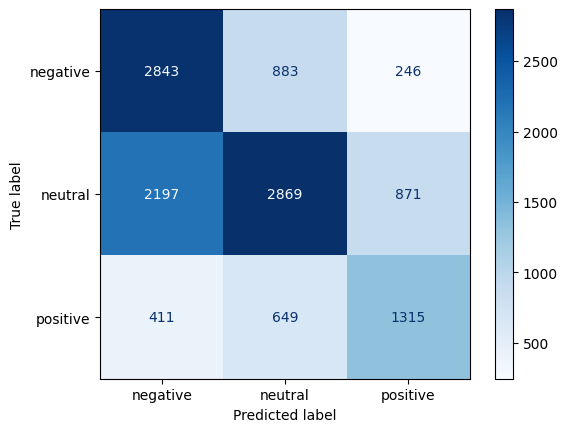

In [ ]:
best = models["LogisticRegression"]   # pick whichever scored higher
y_pred = best.predict(X_test)

print(classification_report(test["label"], y_pred, target_names=labels))
print("Macro F1:   ", f1_score(test["label"], y_pred, average="macro"))
print("Weighted F1:", f1_score(test["label"], y_pred, average="weighted"))

ConfusionMatrixDisplay.from_predictions(test["label"], y_pred, display_labels=labels, cmap="Blues")
plt.show()

In [ ]:
def predict(texts):
    return [labels[i] for i in best.predict(vectorizer.transform([preprocess(t) for t in texts]))]

predict(["I love this phone!", "This was a terrible experience", "The meeting is at 5pm"])

['positive', 'negative', 'neutral']